In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
import pandas as pd

In [3]:
import re
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [4]:
df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
df

,ID,Prediction
0,1,A B C
1,2,A B C
2,3,A B C
3,4,A B C
4,5,A B C
...,...,...
495,496,A B C
496,497,A B C
497,498,A B C
498,499,A B C


In [5]:
df.to_csv("submission.csv", index=False)

In [6]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
train

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A
...,...,...,...,...,...,...,...,...
1995,1996,What is the piezoelectric strain coefficient f...,d = 1.9·10‑12 m/V,d = 3.1·10‑12 m/V,d = 4.2·10‑12 m/V,d = 2.5·10‑12 m/V,d = 5.8·10‑12 m/V,B
1996,1997,Identify the correct statement: What is the sy...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,E
1997,1998,Determine the correct option: What does Earnsh...,A collection of point charges can be maintaine...,A collection of point charges can be maintaine...,A collection of point charges can be maintaine...,A collection of point charges cannot be mainta...,A collection of point charges can be maintaine...,D
1998,1999,Identify the correct statement: What is the re...,The atmosphere is a mechanism that is only inf...,"The atmosphere possesses both chaos and order,...",The atmosphere is a structure that is only inf...,The atmosphere is a completely chaotic mechani...,The atmosphere is a completely ordered structu...,B


In [7]:
test= pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
test

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...
...,...,...,...,...,...,...,...
495,496,What are the constituents of cold dark matter?,"They are unknown, but possibilities include la...",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.
496,497,Pick the best possible answer: What is a plane...,A framework of planets that are all located in...,A mechanism of planets that are all the same s...,Any set of gravitationally bound non-stellar o...,A mechanism of planets that are all located in...,A structure of planets that are all made of gas.
497,498,Pick the best possible answer: What is magneti...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...
498,499,Determine the correct option: What is the evid...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The star S2 follows an elliptical orbit with a...


In [8]:
sample_sub = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
sample_sub

,ID,Prediction
0,1,A B C
1,2,A B C
2,3,A B C
3,4,A B C
4,5,A B C
...,...,...
495,496,A B C
496,497,A B C
497,498,A B C
498,499,A B C


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [10]:
train.head(1)

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B


In [11]:
train.shape

(2000, 8)

In [12]:
test.shape

(500, 7)

In [13]:
train.columns

Index(['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'], dtype='object')

In [14]:
train.isna().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [15]:
Options = ["A", "B", "C", "D", "E"]
train[["prompt"] + Options].isna().sum().to_string()

'prompt    0\nA         0\nB         0\nC         0\nD         0\nE         0'

In [16]:
train[['prompt']+Options].isna().any(axis=1).sum()

np.int64(0)

In [17]:
test[["prompt"] + Options].isna().sum().to_string()

'prompt    0\nA         0\nB         0\nC         0\nD         0\nE         0'

In [18]:
test[['prompt']+Options].isna().any(axis=1).sum()

np.int64(0)

In [19]:
vc = train["answer"].value_counts()
vc

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

In [20]:
vnc = train["answer"].value_counts(normalize=True).round(4)
vnc

answer
B    0.2450
C    0.2295
A    0.1845
D    0.1790
E    0.1620
Name: proportion, dtype: float64

In [21]:
train["answer"].value_counts().to_string()

'answer\nB    490\nC    459\nA    369\nD    358\nE    324'

In [22]:
train["answer"].value_counts(normalize=True).round(4).to_string()

'answer\nB    0.2450\nC    0.2295\nA    0.1845\nD    0.1790\nE    0.1620'

In [23]:
def apk(actual, pred, k=3):
    pred = pred[:k]
    return 1.0 / (pred.index(actual) + 1) if actual in pred else 0.0

In [24]:
def mapk(actuals, preds):
    return float(np.mean([apk(a, p) for a, p in zip(actuals, preds)]))

In [25]:
top3  = vc.index[:3].tolist()
top3

['B', 'C', 'A']

In [26]:
naive = mapk(train["answer"].tolist(), [top3] * len(train))
naive

0.42125

In [27]:
for c in ["prompt"] + Options:
    train[c] = train[c].fillna("").astype(str)
    test[c] = test[c].fillna("").astype(str)

when there is no missing values, then why this step??

In [28]:
plen = train["prompt"].str.split().apply(len)
olen = pd.concat([train[c].str.split().apply(len) for c in Options])

plen

0       22
1        5
2       27
3       19
4       15
        ..
1995    10
1996    16
1997    13
1998    37
1999    18
Name: prompt, Length: 2000, dtype: int64

In [29]:
olen

0       51
1       62
2        1
3       51
4       36
        ..
1995     4
1996    17
1997    22
1998    12
1999    59
Length: 10000, dtype: int64

In [30]:
plen.describe().round(1)

count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0
Name: prompt, dtype: float64

In [31]:
print(f"95th pct : {plen.quantile(0.95):.0f} words")

95th pct : 31 words


In [32]:
olen.describe().round(1)

count    10000.0
mean        26.3
std         17.6
min          1.0
25%         13.0
50%         23.0
75%         36.0
max        118.0
dtype: float64

In [33]:
print(f"95th pct : {olen.quantile(0.95):.0f} words")

95th pct : 61 words


In [34]:
p95 = int(plen.quantile(0.95))
o95 = int(olen.quantile(0.95))

In [35]:
print(f"\nSafe tokenizer max_length estimate : {p95 + o95} words -> ~{(p95+o95)*2} BPE tokens")



Safe tokenizer max_length estimate : 92 words -> ~184 BPE tokens


In [36]:
print("Raw first 60 characters of first 25 prompts")
for p in train["prompt"].head(25):
    print(repr(p[:70]))

Raw first 60 characters of first 25 prompts
"Pick the best possible answer: What is Martin Heidegger's view on the "
'What is accelerator-based light-ion fusion?'
'Determine the correct option: What is the term used in astrophysics to'
"Select the most accurate option: What is Martin Heidegger's view on th"
'Identify the correct statement: What is the concept of simultaneity in'
'Identify the correct statement: What is the effect generated by a spin'
'Which of the following is correct? What is a "coffee ring" in physics?'
'Select the most accurate option: What is the Liouville density? among '
'Select the most accurate option: What are the constituents of cold dar'
'Which of the following is correct? What is the relationship between th'
'Select the most accurate option: What is the Peierls bracket in canoni'
'Choose the correct answer: What is the throttling process, and why is '
'Choose the correct answer: Which of the following statements accuratel'
'What is the interpretation of sup

#### my observations:-
Instruction phrases like "Pick the best possible answer: What..."
    # always end with ": " immediately before the actual question word

    Special case: "Which of the following is correct? What..."

    Text that appears AFTER the main question mark
     e.g. "What is X? carefully." → "carefully"
    

In [37]:
import re

def extract_prefix(t: str) -> str:
    m = re.match(r"^(.*?)(What|Which|Who|How|Why|Determine|Identify|Select|Pick|Choose|The|A |An )", t)
    return m.group(1).strip() if m else ""


In [38]:
prefixes = train["prompt"].apply(extract_prefix)
prefixes

0        
1        
2        
3        
4        
       ..
1995     
1996     
1997     
1998     
1999     
Name: prompt, Length: 2000, dtype: object

In [39]:
print("All unique prefix phrases found in train")
print(prefixes[prefixes != ""].value_counts().to_string())

All unique prefix phrases found in train
Series([], )


In [40]:
def extract_suffix(t: str) -> str:
    parts = t.rstrip().split(".")
    last = parts[-1].strip() if parts else ""
    return last if len(last.split()) <= 6 else ""   

suffixes = train["prompt"].apply(extract_suffix)
print("All unique suffix phrases found in train")
print(suffixes[suffixes != ""].value_counts().head(20).to_string())

All unique suffix phrases found in train
prompt
512 between magnitudes in astronomy?           3
2?                                             2
What is the spin quantum number?               1
What is a pycnometer?                          1
What is accelerator-based light-ion fusion?    1
What is the Kutta condition?                   1
What is the butterfly effect?                  1
What is a Schwarzschild black hole?            1
What is the definition of Atomristor?          1
What is a light-year?                          1
What is the Droste effect?                     1
What is the Roche limit?                       1
What is the Carnot engine?                     1
What is spatial dispersion?                    1
What is emissivity?                            1
What is a virtual particle?                    1
What is the interstellar medium (ISM)?         1
What is indirect photophoresis?                1
What is Minkowski space?                       1
What is the Ozma Prob

In [41]:
def extract_prefix_v2(t: str) ->str:
    m = re.match(r"^([A-Z][^:]+:\s+)(What|Which|Who|How|Why)", t)
    
    if m:
        return m.group(1).strip()
        
    m2 = re.match(r"^(Which of the following is correct\?)\s+", t)
    if m2:
        return m2.group(1)
    return "NONE"

In [42]:
def extract_suffix_v2(t: str) -> str:
    
    parts = t.split("?")
    
    if len(parts) > 1:
        
        suffix = parts[-1].strip().rstrip(".")
        
        if suffix and 1 <= len(suffix.split()) <= 8:
            return suffix
            
    return "NONE"

In [43]:
train["prefix_type"] = train["prompt"].apply(extract_prefix_v2)
train["suffix_type"] = train["prompt"].apply(extract_suffix_v2)
train["prefix_type"]

0         Pick the best possible answer:
1                                   NONE
2          Determine the correct option:
3       Select the most accurate option:
4        Identify the correct statement:
                      ...               
1995                                NONE
1996     Identify the correct statement:
1997       Determine the correct option:
1998     Identify the correct statement:
1999      Pick the best possible answer:
Name: prefix_type, Length: 2000, dtype: object

In [44]:
train["suffix_type"]

0         among the listed options
1                             NONE
2         among the listed options
3                        carefully
4                        carefully
                   ...            
1995                          NONE
1996    based on the given context
1997    from the following choices
1998    from the following choices
1999                     carefully
Name: suffix_type, Length: 2000, dtype: object

In [45]:
print("All unique PREFIXES found")
print(train["prefix_type"].value_counts().to_string())

All unique PREFIXES found
prefix_type
Pick the best possible answer:        316
Select the most accurate option:      309
Identify the correct statement:       302
Determine the correct option:         299
Choose the correct answer:            292
Which of the following is correct?    282
NONE                                  200


In [46]:
print("All unique SUFFIXES found")
print(train["suffix_type"].value_counts().to_string())

All unique SUFFIXES found
suffix_type
NONE                          538
among the listed options      388
based on the given context    376
from the following choices    369
carefully                     329


In [47]:
combo = train.groupby(["prefix_type","suffix_type"]).size().reset_index(name="count")

print(f"Total unique prefix×suffix combinations: {len(combo)}")

print(f"Rows with NEITHER prefix NOR suffix (bare questions): "
      f"{((train['prefix_type']=='NONE') & (train['suffix_type']=='NONE')).sum()}")

print("\nTop 15 prefix×suffix combinations:")

print(combo.sort_values("count", ascending=False).head(15).to_string(index=False))

Total unique prefix×suffix combinations: 31
Rows with NEITHER prefix NOR suffix (bare questions): 200

Top 15 prefix×suffix combinations:
                       prefix_type                suffix_type  count
                              NONE                       NONE    200
  Select the most accurate option: based on the given context     72
   Identify the correct statement:   among the listed options     71
    Pick the best possible answer:   among the listed options     70
   Identify the correct statement: based on the given context     69
     Determine the correct option:   among the listed options     69
    Pick the best possible answer: from the following choices     68
        Choose the correct answer: based on the given context     67
  Select the most accurate option:   among the listed options     67
  Select the most accurate option:                  carefully     66
    Pick the best possible answer:                       NONE     65
Which of the following is correct?

In [48]:
PREFIX_PATTERNS = [
    r"^pick the best possible answer:?\s*",
    r"^select the most accurate option:?\s*",
    r"^determine the correct option:?\s*",
    r"^identify the correct statement:?\s*",
    r"^which of the following is correct\??\s*",
    r"^choose the correct answer:?\s*",
]

In [49]:
SUFFIX_PATTERNS = [
    r"\s*carefully\.?$",
    r"\s*based on the given context\.?$",
    r"\s*from the following choices\.?$",
    r"\s*among the listed options\.?$",
]

Why we have used above pattern? how did we find that? we haven't shown that why or the thought process of that?

In [50]:
import re

In [51]:
def strip_wrapper(t: str) -> str:
    t = t.lower().strip()
    for p in PREFIX_PATTERNS: t = re.sub(p, "", t)
    for p in SUFFIX_PATTERNS: t = re.sub(p, "", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

In [52]:
train["core"] = train["prompt"].apply(strip_wrapper)
test["core"] = test["prompt"].apply(strip_wrapper)
train["core"]

0       what is martin heidegger s view on the relatio...
1              what is accelerator based light ion fusion
2       what is the term used in astrophysics to descr...
3       what is martin heidegger s view on the relatio...
4       what is the concept of simultaneity in einstei...
                              ...                        
1995    what is the piezoelectric strain coefficient f...
1996          what is the synapstor or synapse transistor
1997                   what does earnshaw s theorem state
1998    what is the revised view of the atmosphere s n...
1999    which of the following statements accurately d...
Name: core, Length: 2000, dtype: object

In [53]:
train["group"] = train["core"].astype("category").cat.codes
train["group"]

0        51
1        39
2       202
3        51
4        72
       ... 
1995    142
1996    201
1997     16
1998    179
1999    231
Name: group, Length: 2000, dtype: int16

In [54]:
dup = train["core"].value_counts()
dup

core
what is the definition of an improper rotation                                                                                                                                21
what is the significance of the high degree of fatty acyl disorder in the thylakoid membranes of plants                                                                       20
what was the aim of the gravity probe b gp b mission                                                                                                                          18
what is the gravitomagnetic interaction                                                                                                                                       18
which of the following statements accurately describes the impact of modified newtonian dynamics mond on the observed missing baryonic mass discrepancy in galaxy clusters    16
                                                                                                              

In [55]:
print(f"Total train rows : {len(train)}")
print(f"Unique core questions : {dup.shape[0]}")
print(f"Avg copies per question : {len(train)/dup.shape[0]:.1f}x")
print(f"Clusters with >1 copy : {(dup>1).sum()}")
print(f"Rows inside duplicate clusters: {dup[dup>1].sum()}")
print(f"\nTop 10 largest duplicate clusters:")
print(dup.head(10).to_string())


Total train rows : 2000
Unique core questions : 252
Avg copies per question : 7.9x
Clusters with >1 copy : 222
Rows inside duplicate clusters: 1970

Top 10 largest duplicate clusters:
core
what is the definition of an improper rotation                                                                                                                                21
what is the significance of the high degree of fatty acyl disorder in the thylakoid membranes of plants                                                                       20
what was the aim of the gravity probe b gp b mission                                                                                                                          18
what is the gravitomagnetic interaction                                                                                                                                       18
which of the following statements accurately describes the impact of modified newtonian dynamics mond o

In [56]:
# Are all copies of the same question labeled with the same answer?
consistent = train.groupby("core")["answer"].apply(lambda s: s.nunique() == 1)
print(f"\nClusters with 100% consistent answer: {consistent.sum()}/{len(consistent)} ({consistent.mean():.1%})")


Clusters with 100% consistent answer: 252/252 (100.0%)


In [57]:
dup_test = test["core"].value_counts()
overlap = set(train["core"]) & set(test["core"])
overlap

{'how do the lunar laser ranging experiment radar astronomy and the deep space network determine distances to the moon planets and spacecraft',
 'how many crystallographic point groups are there in three dimensional space',
 'what are amorphous ferromagnetic metallic alloys and what are their advantages',
 'what are coherent turbulent structures',
 'what are permutation inversion groups',
 'what are some models that attempt to account for all observations without invoking supplemental non baryonic matter',
 'what are the constituents of cold dark matter',
 'what are the four qualitative levels of crystallinity described by geologists',
 'what are the navier stokes equations',
 'what are the two main factors that cause resistance in a metal',
 'what are the two main interpretations for the disparity between the presence of matter and antimatter in the observable universe',
 'what can be inferred about the electronic entropy of insulators and metals based on their densities of states at 

In [58]:
print(f"Unique core questions in test : {dup_test.shape[0]}")
print(f"Of those, already seen in train (exact) : {len(overlap)} ({len(overlap)/dup_test.shape[0]:.1%})")
print(f"Test rows with a direct retrieval match : {test['core'].isin(set(train['core'])).sum()} / {len(test)}")
print(f"Duplicate clusters inside test : {(dup_test>1).sum()}")


Unique core questions in test : 228
Of those, already seen in train (exact) : 228 (100.0%)
Test rows with a direct retrieval match : 500 / 500
Duplicate clusters inside test : 153


In [59]:
print(f"\nFirst 5 overlapping core questions:")
for q in list(overlap)[:5]:
    print(f" -> {q[:100]}")


First 5 overlapping core questions:
 -> what is a virtual particle
 -> what is the significance of the speed of light in vacuum
 -> what are the two main interpretations for the disparity between the presence of matter and antimatte
 -> what is the si unit of the physical quantity m q
 -> what is the origin of the permanent moment in paramagnetism


In [60]:
from itertools import combinations

In [61]:
def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a | b) else 0.0

In [62]:
def tok_set(t: str) -> set:
    return set(re.findall(r"[a-z0-9]+", t.lower()))

In [63]:
avg_overlap_list = []
margin_list = []

In [64]:
for _, row in train.iterrows():
    opt_sets = {c: tok_set(row[c]) for c in Options}
    pairs = list(combinations(Options, 2))
    avg_overlap_list.append(np.mean([jaccard(opt_sets[a], opt_sets[b]) for a, b in pairs]))

    pset = tok_set(row["prompt"])
    correct = row["answer"]
    c_ov = jaccard(pset, opt_sets[correct])
    i_ov = np.mean([jaccard(pset, opt_sets[c]) for c in Options if c != correct])
    margin_list.append(c_ov - i_ov)

In [65]:
avg_overlap_s = pd.Series(avg_overlap_list)
margin_s = pd.Series(margin_list)
avg_overlap_s

0       0.306770
1       0.760694
2       0.000000
3       0.306770
4       0.451501
          ...   
1995    0.613889
1996    0.846537
1997    0.814206
1998    0.240302
1999    0.940000
Length: 2000, dtype: float64

In [66]:
margin_s 

0      -0.057184
1      -0.007469
2       0.000000
3      -0.061263
4      -0.007368
          ...   
1995    0.000000
1996    0.000000
1997    0.000980
1998   -0.033425
1999    0.000000
Length: 2000, dtype: float64

In [67]:
print(avg_overlap_s.describe().round(3).to_string())
print(f"\nQuestions where options are >50% similar: {(avg_overlap_s > 0.5).mean():.1%}")

count    2000.000
mean        0.516
std         0.267
min         0.000
25%         0.300
50%         0.535
75%         0.764
max         0.940

Questions where options are >50% similar: 53.1%


In [68]:
print(margin_s.describe().round(4).to_string())
print(f"\nCorrect option is NOT the most lexically similar to prompt: {(margin_s <= 0).mean():.1%}")

count    2000.0000
mean       -0.0117
std         0.0352
min        -0.1612
25%        -0.0247
50%        -0.0040
75%         0.0010
max         0.1597

Correct option is NOT the most lexically similar to prompt: 73.7%


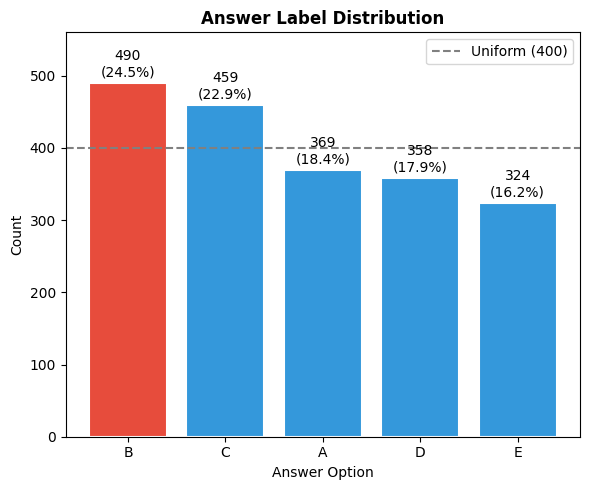

In [69]:
plt.figure(figsize=(6,5))

vc = train["answer"].value_counts()
colors = ["#e74c3c" if v == vc.max() else "#3498db" for v in vc.values]

bars = plt.bar(vc.index, vc.values, color=colors, edgecolor="white", linewidth=1.5)
plt.axhline(y=len(train)/5, color="gray", linestyle="--", linewidth=1.5, label="Uniform (400)")

for bar, val in zip(bars, vc.values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
             f"{val}\n({val/len(train)*100:.1f}%)",
             ha="center", va="bottom", fontsize=10)

plt.title("Answer Label Distribution", fontweight="bold")
plt.xlabel("Answer Option")
plt.ylabel("Count")
plt.legend()
plt.ylim(0, 560)

plt.tight_layout()
plt.show()

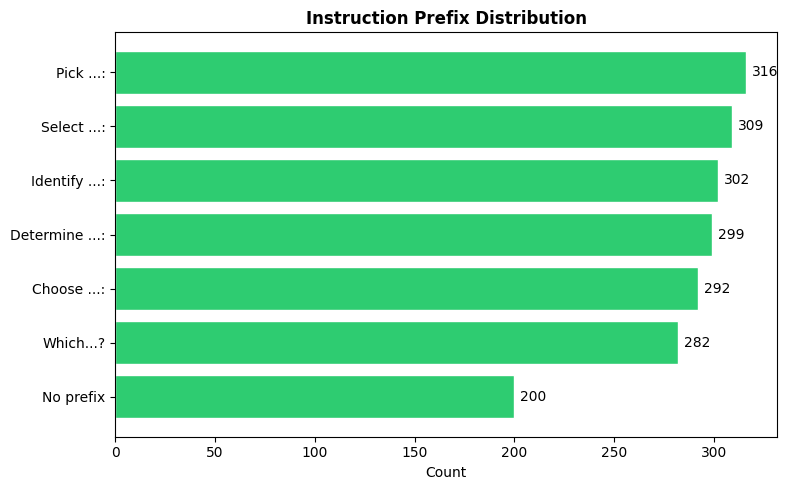

In [70]:
plt.figure(figsize=(8,5))

pvc = train["prefix_type"].value_counts()

short_labels = [
    p.replace("the best possible answer","...")
     .replace("the most accurate option","...")
     .replace("the correct option","...")
     .replace("the correct statement","...")
     .replace("the correct answer","...")
     .replace("Which of the following is correct?","Which...?")
     .replace("NONE","No prefix")
    for p in pvc.index
]

plt.barh(short_labels, pvc.values, color="#2ecc71", edgecolor="white")

for i, v in enumerate(pvc.values):
    plt.text(v+3, i, str(v), va="center", fontsize=10)

plt.title("Instruction Prefix Distribution", fontweight="bold")
plt.xlabel("Count")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

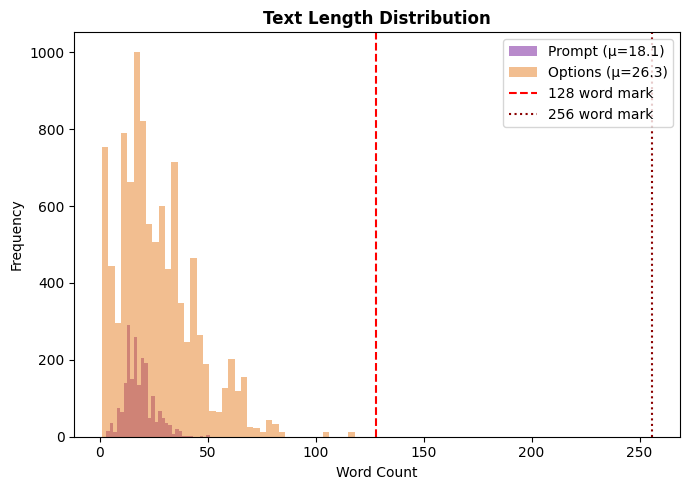

In [71]:
plt.figure(figsize=(7,5))

plen = train["prompt"].str.split().apply(len)
olen = pd.concat([train[c].str.split().apply(len) for c in Options])

plt.hist(plen, bins=30, alpha=0.7, color="#9b59b6",
         label=f"Prompt (μ={plen.mean():.1f})")

plt.hist(olen, bins=40, alpha=0.5, color="#e67e22",
         label=f"Options (μ={olen.mean():.1f})")

plt.axvline(x=128, color="red", linestyle="--", linewidth=1.5,
            label="128 word mark")
plt.axvline(x=256, color="darkred", linestyle=":", linewidth=1.5,
            label="256 word mark")

plt.title("Text Length Distribution", fontweight="bold")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

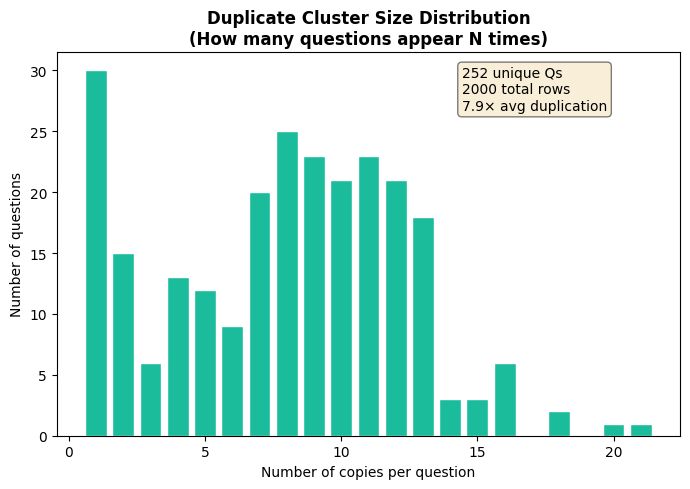

In [72]:
plt.figure(figsize=(7,5))

PREFIX_PATTERNS = [
    r"^pick the best possible answer:?\s*",
    r"^select the most accurate option:?\s*",
    r"^determine the correct option:?\s*",
    r"^identify the correct statement:?\s*",
    r"^which of the following is correct\??\s*",
    r"^choose the correct answer:?\s*"
]

SUFFIX_PATTERNS = [
    r"\s*carefully\.?$",
    r"\s*based on the given context\.?$",
    r"\s*from the following choices\.?$",
    r"\s*among the listed options\.?$"
]

def strip_wrapper(t):
    t = t.lower().strip()
    for p in PREFIX_PATTERNS:
        t = re.sub(p, "", t)
    for p in SUFFIX_PATTERNS:
        t = re.sub(p, "", t)
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9\s]", " ", t)).strip()

train["core"] = train["prompt"].apply(strip_wrapper)

dup = train["core"].value_counts()
cluster_sizes = dup.value_counts().sort_index()

plt.bar(cluster_sizes.index, cluster_sizes.values,
        color="#1abc9c", edgecolor="white")

plt.title(
    "Duplicate Cluster Size Distribution\n(How many questions appear N times)",
    fontweight="bold"
)

plt.xlabel("Number of copies per question")
plt.ylabel("Number of questions")

plt.text(
    0.65,
    0.85,
    "252 unique Qs\n2000 total rows\n7.9× avg duplication",
    transform=plt.gca().transAxes,
    fontsize=10,
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5)
)

plt.tight_layout()
plt.show()

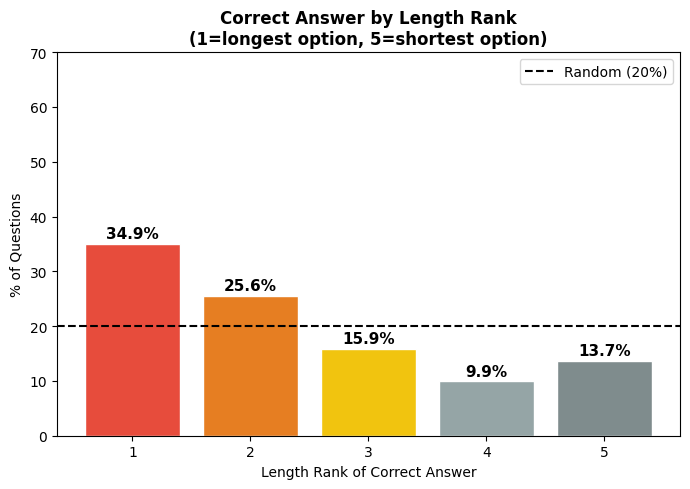

In [73]:
plt.figure(figsize=(7,5))

def answer_length_rank(row):
    lens = sorted(
        [(c, len(row[c].split())) for c in Options],
        key=lambda x: -x[1]
    )
    rank_map = {c: r+1 for r, (c, _) in enumerate(lens)}
    return rank_map[row["answer"]]

train["ans_len_rank"] = train.apply(answer_length_rank, axis=1)

rank_counts = train["ans_len_rank"].value_counts().sort_index()
rank_pct = rank_counts / len(train) * 100

bars = plt.bar(
    rank_counts.index,
    rank_pct.values,
    color=["#e74c3c","#e67e22","#f1c40f","#95a5a6","#7f8c8d"],
    edgecolor="white"
)

plt.axhline(y=20, color="black", linestyle="--",
            linewidth=1.5, label="Random (20%)")

for bar, val in zip(bars, rank_pct.values):
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.5,
        f"{val:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Correct Answer by Length Rank\n(1=longest option, 5=shortest option)",
    fontweight="bold"
)

plt.xlabel("Length Rank of Correct Answer")
plt.ylabel("% of Questions")
plt.legend()
plt.ylim(0, 70)

plt.tight_layout()
plt.show()

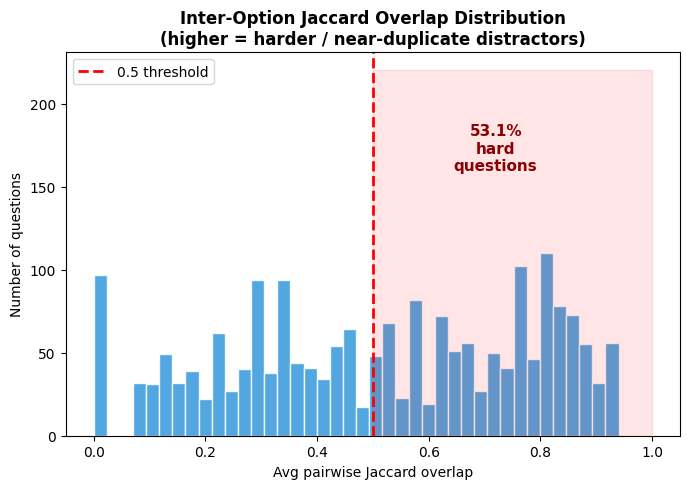

In [74]:
from itertools import combinations

plt.figure(figsize=(7,5))

def jac(a, b):
    return len(a & b) / len(a | b) if a | b else 0.0

def toks(t):
    return set(re.findall(r"[a-z0-9]+", t.lower()))

ov_list = [
    np.mean([
        jac(toks(row[a]), toks(row[b]))
        for a, b in combinations(Options, 2)
    ])
    for _, row in train.iterrows()
]

ov_s = pd.Series(ov_list)

plt.hist(
    ov_s,
    bins=40,
    color="#3498db",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    label="0.5 threshold"
)

plt.fill_betweenx([0,220], 0.5, 1.0, alpha=0.1, color="red")

plt.text(
    0.72,
    160,
    f"{(ov_s>0.5).mean():.1%}\nhard\nquestions",
    ha="center",
    fontsize=11,
    color="darkred",
    fontweight="bold"
)

plt.title(
    "Inter-Option Jaccard Overlap Distribution\n(higher = harder / near-duplicate distractors)",
    fontweight="bold"
)

plt.xlabel("Avg pairwise Jaccard overlap")
plt.ylabel("Number of questions")
plt.legend()

plt.tight_layout()
plt.show()

In [75]:
print(f"\nThe LONGEST option is the correct answer: {(train['ans_len_rank']==1).mean():.1%} of the time")
print(f"Random baseline would be:                  20.0%")
print(f"Lift over random:                          {(train['ans_len_rank']==1).mean()/0.20:.1f}x")



The LONGEST option is the correct answer: 34.9% of the time
Random baseline would be:                  20.0%
Lift over random:                          1.7x


In [76]:
train["option_overlap"] = [
    np.mean([jaccard(tok_set(row[a]), tok_set(row[b]))
             for a, b in combinations(Options, 2)])
    for _, row in train.iterrows()
]
train["option_overlap"]

0       0.306770
1       0.760694
2       0.000000
3       0.306770
4       0.451501
          ...   
1995    0.613889
1996    0.846537
1997    0.814206
1998    0.240302
1999    0.940000
Name: option_overlap, Length: 2000, dtype: float64

In [77]:
print(f"option_overlap column added. Range: {train['option_overlap'].min():.3f} - {train['option_overlap'].max():.3f}")

option_overlap column added. Range: 0.000 - 0.940


In [78]:
print("HARDEST question (options 94% identical by word overlap)")
print("The correct answer differs by a SINGLE SYMBOL from two wrong options")

hardest = train.loc[train["option_overlap"].idxmax()]
print(f"\nPrompt  : {hardest['prompt']}")
print(f"Overlap : {hardest['option_overlap']:.3f}")
print(f"Correct : {hardest['answer']}\n")

HARDEST question (options 94% identical by word overlap)
The correct answer differs by a SINGLE SYMBOL from two wrong options

Prompt  : Which of the following statements accurately describes the characteristics of gravitational waves?
Overlap : 0.940
Correct : C



In [79]:
for c in Options:
    marker = " <-- CORRECT" if hardest["answer"] == c else ""
    print(f"  {c}: {hardest[c][:120]}{marker}")

  A: Gravitational waves have an amplitude denoted by h, which represents the size of the wave. The amplitude varies with tim
  B: Gravitational waves have an amplitude denoted by λ, which represents the distance between points of maximum stretch or s
  C: Gravitational waves have an amplitude denoted by h, which represents the size of the wave. The amplitude varies with tim <-- CORRECT
  D: Gravitational waves have an amplitude denoted by f, which represents the frequency of the wave's oscillation. The amplit
  E: Gravitational waves have an amplitude denoted by f, which represents the frequency of the wave's oscillation. The amplit


##### Observation: 
Options A and C are IDENTICAL in first 120 characters.
Options D and E are IDENTICAL to each other.
The only differentiator is the symbol used: h (correct) vs λ vs f.
A bag-of-words model sees the same token set in all 5 options.
Only a model that understands what these symbols mean can answer this.

In [80]:
print("EASIEST QUESTION - options share zero vocabulary")


easiest = train.loc[train["option_overlap"].idxmin()]
print(f"\nPrompt  : {easiest['prompt']}")
print(f"Overlap : {easiest['option_overlap']:.3f}")
print(f"Correct : {easiest['answer']}\n")


EASIEST QUESTION - options share zero vocabulary

Prompt  : Determine the correct option: What is the term used in astrophysics to describe light-matter interactions resulting in energy shifts in the radiation field? among the listed options.
Overlap : 0.000
Correct : C



In [81]:
for c in Options:
    marker = " <-- CORRECT" if easiest["answer"] == c else ""
    print(f"  {c}: {easiest[c]}{marker}")

  A: Blueshifting
  B: Redshifting
  C: Reddening <-- CORRECT
  D: Whitening
  E: Yellowing


In [82]:
def get_question_word(t: str) -> str:
    # Strip instruction prefix first, then find the actual question word
    t_stripped = re.sub(r"^[A-Z][^:]+:\s*", "", t)
    m = re.match(r"^(What|Which|Who|How|Why)\b", t_stripped, re.I)
    return m.group(1).lower() if m else "other"

In [83]:
train["q_word"] = train["prompt"].apply(get_question_word)
train["q_word"].value_counts()

q_word
what     1534
which     383
who        55
how        26
other       2
Name: count, dtype: int64

In [84]:
print("QUESTION WORD DISTRIBUTION:")
qw = train["q_word"].value_counts()
print(qw.to_string())
print(f"\n→ {qw['what']/len(train):.1%} of questions are 'What is...' factual definition questions")
print(f"→ {qw['which']/len(train):.1%} are 'Which of the following...' statement-evaluation questions")
print(f"→ These two types require different reasoning strategies:")
print(f"   'What' = retrieve the correct fact")
print(f"   'Which' = evaluate which statement correctly describes a fact")

QUESTION WORD DISTRIBUTION:
q_word
what     1534
which     383
who        55
how        26
other       2

→ 76.7% of questions are 'What is...' factual definition questions
→ 19.1% are 'Which of the following...' statement-evaluation questions
→ These two types require different reasoning strategies:
   'What' = retrieve the correct fact
   'Which' = evaluate which statement correctly describes a fact


In [85]:
DOMAIN_KEYWORDS = {
    "Physics / Astronomy" : [
        "quantum", "photon", "relativity", "force", "energy", "wave", "spin",
        "field", "entropy", "gravity", "superconductor", "boson", "fermion",
        "hamiltonian", "symmetry", "thermodynamic", "star", "galaxy", "pulsar",
        "redshift", "supernova", "universe", "dark matter", "black hole"
    ],
    "Chemistry / Materials" : [
        "molecule", "ion", "bond", "acid", "reaction", "enzyme", "protein",
        "membrane", "polymer", "crystal", "alloy", "metal", "orbital", "catalyst",
        "ferromagnetic", "memristor", "piezoelectric"
    ],
    "Biology" : [
        "cell", "gene", "organism", "evolution", "mammal", "plant", "bacteria",
        "virus", "dna", "rna", "chromosome", "phage", "myrmecophyte", "mammary"
    ],
    "Math / CS" : [
        "function", "theorem", "matrix", "vector", "topology", "algebra", "group",
        "manifold", "integral", "algorithm", "polytope", "quantization"
    ],
}
#DOMAIN_KEYWORDS

In [86]:
def classify_domain(t: str) -> str:
    t_low = t.lower()
    scores = {d: sum(1 for kw in kws if kw in t_low) for d, kws in DOMAIN_KEYWORDS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "General / Other"


In [87]:
train["domain"] = (train["prompt"] + " " + train["A"] + " " + train["B"]).apply(classify_domain)

print("SUBJECT DOMAIN DISTRIBUTION:")
domain_counts = train["domain"].value_counts()
print(domain_counts.to_string())

print("\nCORRECT ANSWER DISTRIBUTION BY DOMAIN:")
for d in domain_counts.index:
    subset = train[train["domain"] == d]
    dist = subset["answer"].value_counts(normalize=True).round(3).to_dict()
    print(f"  {d} (n={len(subset):4d}): {dist}")

SUBJECT DOMAIN DISTRIBUTION:
domain
Physics / Astronomy      955
Chemistry / Materials    857
General / Other          106
Biology                   42
Math / CS                 40

CORRECT ANSWER DISTRIBUTION BY DOMAIN:
  Physics / Astronomy (n= 955): {'C': 0.251, 'B': 0.203, 'D': 0.193, 'A': 0.18, 'E': 0.173}
  Chemistry / Materials (n= 857): {'B': 0.31, 'C': 0.186, 'A': 0.181, 'D': 0.162, 'E': 0.161}
  General / Other (n= 106): {'C': 0.283, 'B': 0.208, 'E': 0.198, 'D': 0.189, 'A': 0.123}
  Biology (n=  42): {'A': 0.452, 'D': 0.357, 'C': 0.19}
  Math / CS (n=  40): {'C': 0.55, 'A': 0.25, 'B': 0.2}


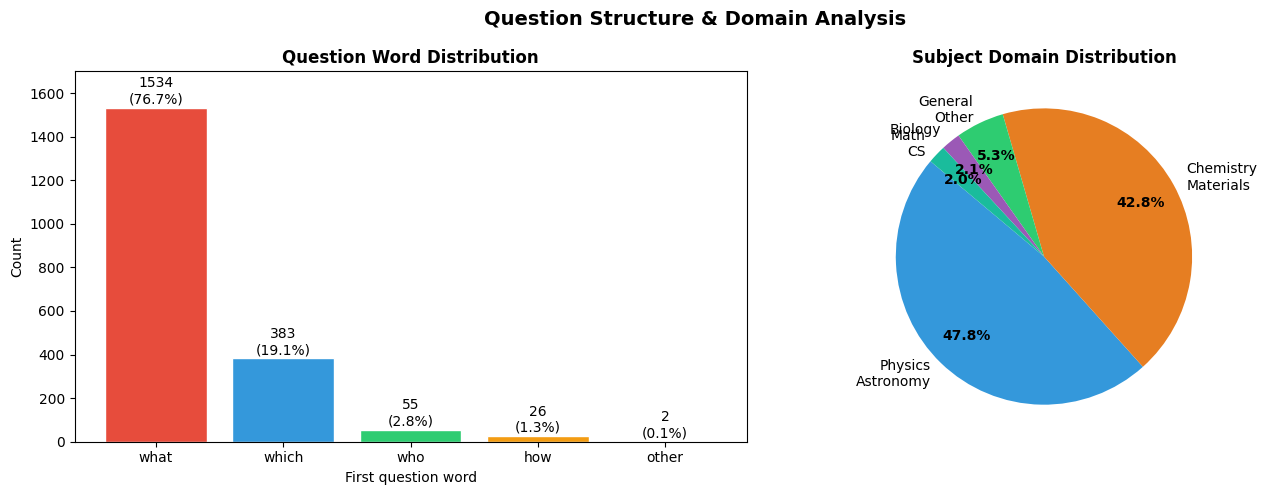

Saved: eda_domain_plots.png


In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Question Structure & Domain Analysis", fontsize=14, fontweight="bold")

ax = axes[0]
qw_plot = train["q_word"].value_counts()
colors_qw = ["#e74c3c","#3498db","#2ecc71","#f39c12","#9b59b6"]
bars = ax.bar(qw_plot.index, qw_plot.values,
              color=colors_qw[:len(qw_plot)], edgecolor="white")
for bar, val in zip(bars, qw_plot.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
            f"{val}\n({val/len(train)*100:.1f}%)",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Question Word Distribution", fontweight="bold")
ax.set_xlabel("First question word")
ax.set_ylabel("Count")
ax.set_ylim(0, 1700)

ax = axes[1]
dc = train["domain"].value_counts()
short_labels = [d.replace(" / ", "\n") for d in dc.index]
colors_d = ["#3498db","#e67e22","#2ecc71","#9b59b6","#1abc9c"]
wedges, texts, autotexts = ax.pie(
    dc.values,
    labels=short_labels,
    autopct="%1.1f%%",
    colors=colors_d[:len(dc)],
    startangle=140,
    pctdistance=0.75,
    textprops={"fontsize": 10}
)
for at in autotexts:
    at.set_fontweight("bold")
ax.set_title("Subject Domain Distribution", fontweight="bold")

plt.tight_layout()
plt.savefig("eda_domain_plots.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: eda_domain_plots.png")

## Q1-Milestone1
**Calculate the frequency distribution of the correct  answer  (A, B, C, D, E) in train.csv. Based on your counts, what is the sum of the occurrences of the most frequent option and the least frequent option?**

In [89]:
train['answer'].value_counts().sort_index()

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64

In [90]:
freq = train['answer'].value_counts().sort_index()
freq

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64

In [91]:
freq.min(), freq.max()

(324, 490)

In [92]:
mn = freq.min()
mx = freq.max()
sum = mn+mx
sum

814

## Q2

**After converting the prompt column to lowercase and removing all standard punctuation characters (using Python's string.punctuation), split the text by whitespace. What is the total number of unique words (vocabulary size) across the entire cleaned prompt column of train.csv?**  
*


In [93]:
import string

In [94]:
clean_prompts = (train["prompt"].str.lower().str.translate(str.maketrans('', '', string.punctuation)))

clean_prompts

0       pick the best possible answer what is martin h...
1                what is acceleratorbased lightion fusion
2       determine the correct option what is the term ...
3       select the most accurate option what is martin...
4       identify the correct statement what is the con...
                              ...                        
1995    what is the piezoelectric strain coefficient f...
1996    identify the correct statement what is the syn...
1997    determine the correct option what does earnsha...
1998    identify the correct statement what is the rev...
1999    pick the best possible answer which of the fol...
Name: prompt, Length: 2000, dtype: object

In [95]:
vocab = set()

In [96]:
for text in clean_prompts:
    vocab.update(text.split())

In [97]:
len(vocab)

859

In [98]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [99]:
row1 = train[train["id"] == 1].iloc[0]

In [100]:
prompt = (row1["prompt"].lower().translate(str.maketrans('', '', string.punctuation)))
prompt

'pick the best possible answer what is martin heideggers view on the relationship between time and human existence among the listed options'

In [101]:
words = prompt.split()

filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS
]
filtered_words

['pick',
 'best',
 'possible',
 'answer',
 'martin',
 'heideggers',
 'view',
 'relationship',
 'time',
 'human',
 'existence',
 'listed',
 'options']

In [102]:
len(filtered_words)

13

In [103]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [104]:
combined_text = (
    train["prompt"] + " " +
    train["A"] + " " +
    train["B"] + " " +
    train["C"] + " " +
    train["D"] + " " +
    train["E"]
)
combined_text

0       Pick the best possible answer: What is Martin ...
1       What is accelerator-based light-ion fusion? Ac...
2       Determine the correct option: What is the term...
3       Select the most accurate option: What is Marti...
4       Identify the correct statement: What is the co...
                              ...                        
1995    What is the piezoelectric strain coefficient f...
1996    Identify the correct statement: What is the sy...
1997    Determine the correct option: What does Earnsh...
1998    Identify the correct statement: What is the re...
1999    Pick the best possible answer: Which of the fo...
Length: 2000, dtype: object

In [105]:
vectorizer = TfidfVectorizer(stop_words="english")

In [106]:
X = vectorizer.fit_transform(combined_text)
X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 64180 stored elements and shape (2000, 2762)>

In [107]:
X.shape

(2000, 2762)

In [108]:
from sklearn.metrics.pairwise import cosine_similarity

In [109]:
row1 = train[train["id"] == 1].iloc[0]


In [110]:

prompt_vec = vectorizer.transform([row1["prompt"]])

optionA_vec = vectorizer.transform([row1["A"]])

similarity = cosine_similarity(prompt_vec,optionA_vec)[0][0]

similarity

np.float64(0.27202429519891635)

In [111]:
round(similarity, 4)

np.float64(0.272)

In [112]:
options = ["A","B","C","D","E"]
correct = 0

In [113]:
for _, row in train.iterrows():

    prompt_vec = vectorizer.transform([row["prompt"]])

    scores = {}

    for option in options:

        option_vec = vectorizer.transform([row[option]])

        scores[option] = cosine_similarity(prompt_vec,option_vec)[0][0]

    prediction = max(
        scores,
        key=scores.get
    )

    if prediction == row["answer"]:
        correct += 1

accuracy = (correct / len(train)) * 100

accuracy

13.55

In [114]:
def map3(actual, preds):

    for rank, pred in enumerate(preds[:3], start=1):

        if pred == actual:
            return 1 / rank

    return 0

In [115]:
freq = train["answer"].value_counts()

top3 = freq.index[:3].tolist()

top3

['B', 'C', 'A']

In [116]:
scores = []

for actual in train["answer"]:

    scores.append(
        map3(actual, top3)
    )
np.mean(scores)

np.float64(0.42125)

In [117]:
def map3(actual, preds):

    for rank, pred in enumerate(preds[:3], start=1):

        if pred == actual:
            return 1 / rank

    return 0

In [118]:
options = ["A","B","C","D","E"]

In [119]:
scores = []

In [120]:
for _, row in train.iterrows():

    prompt_vec = vectorizer.transform([row["prompt"]])

    similarities = {}

    for option in options:

        option_vec = vectorizer.transform([row[option]])

        similarities[option] = cosine_similarity(prompt_vec,option_vec)[0][0]

    ranked_options = sorted(
        similarities,
        key=similarities.get,
        reverse=True
    )

    top3 = ranked_options[:3]

    scores.append(
        map3(row["answer"],top3)
    )



In [121]:
np.mean(scores)

np.float64(0.2961666666666667)

## Milestone 2

In [122]:
!pip -q install transformers datasets sentence-transformers accelerate

In [123]:
from datasets import load_dataset

In [124]:
from transformers import (AutoTokenizer,AutoModel,pipeline)


In [125]:
from sentence_transformers import SentenceTransformer, util

In [126]:
import torch

In [127]:
dataset = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)

tr = dataset["train"]

tr

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'],
    num_rows: 2000
})

In [128]:
tr = tr.map(
    lambda x: {
        "combined_text":
        x["prompt"] + " " + x["A"]
    }
)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [129]:
tr[51]

{'id': 52,
 'prompt': 'Determine the correct option: What is the reason behind the designation of Class L dwarfs, and what is their color and composition? among the listed options.',
 'A': 'Class L dwarfs are hotter than M stars and are designated L because L is the remaining letter alphabetically closest to M. They are bright blue in color and are brightest in ultraviolet. Their atmosphere is hot enough to allow metal hydrides and alkali metals to be prominent in their spectra. Some of these objects have masses large enough to support hydrogen fusion and are therefore stars, but most are of substellar mass and are therefore brown dwarfs.',
 'B': 'Class L dwarfs are cooler than M stars and are designated L because L is the remaining letter alphabetically closest to M. They are dark red in color and are brightest in infrared. Their atmosphere is cool enough to allow metal hydrides and alkali metals to be prominent in their spectra. Some of these objects have masses large enough to suppo

In [130]:
combined_text

0       Pick the best possible answer: What is Martin ...
1       What is accelerator-based light-ion fusion? Ac...
2       Determine the correct option: What is the term...
3       Select the most accurate option: What is Marti...
4       Identify the correct statement: What is the co...
                              ...                        
1995    What is the piezoelectric strain coefficient f...
1996    Identify the correct statement: What is the sy...
1997    Determine the correct option: What does Earnsh...
1998    Identify the correct statement: What is the re...
1999    Pick the best possible answer: Which of the fo...
Length: 2000, dtype: object

#### Q1
Load train.csv using the Hugging Face datasets library (do not use pandas). Use the .map() function to create a new column called combined_text that concatenates the prompt and A columns with a space in between. E.g., prompt_text A_text. What is the exact character length (total number of string characters using Python's len() function, NOT the number of tokens) of the combined_text string for the row at index 51? Note: We follow zero-indexing here

In [131]:
len(tr[51]["combined_text"])

614

#### Q2


In [132]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [133]:
tokenizer.vocab_size

30522

#### Q3

In [134]:
tokenizer.sep_token_id

102

#### Q4

In [135]:
encoding = tokenizer(
    list(tr["prompt"]),
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print(encoding["input_ids"].shape)

torch.Size([2000, 128])


In [136]:
def tokenize_function(example):
    return tokenizer(
        example["prompt"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_dataset = tr.map(tokenize_function)

tokenized_dataset

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer', 'combined_text', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})

#### Q6

In [137]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    "bert-base-uncased"
)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [138]:
text = tr[0]["prompt"]

inputs = tokenizer(
    text,
    return_tensors="pt"
)

In [139]:
outputs = model(**inputs)
#outputs

In [140]:
outputs.last_hidden_state.shape

torch.Size([1, 31, 768])

#### Q7

In [141]:
index = 0
cls = outputs.last_hidden_state[0,0]
cls[:5]

tensor([-0.4677, -0.0754, -0.2019, -0.0071, -0.4480], grad_fn=<SliceBackward0>)

In [142]:
round(
    cls[:5].sum().item(),
    4
)

-1.2001

#### Q8

In [143]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    "bert-base-uncased",
    output_attentions=True
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [144]:
text = "Light-ion fusion is a technique."

inputs = tokenizer(
    text,
    return_tensors="pt"
)

In [145]:
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

print(tokens)

['[CLS]', 'light', '-', 'ion', 'fusion', 'is', 'a', 'technique', '.', '[SEP]']


In [146]:
fusion_index = tokens.index("fusion")

print(fusion_index)

4


In [147]:
outputs = model(**inputs)

In [148]:
print(outputs.attentions[-1].shape)

torch.Size([1, 12, 10, 10])


In [149]:
last_layer = outputs.attentions[-1]

head0 = last_layer[0, 0]

In [150]:
attention = head0[0, fusion_index]

print(attention)
print(round(attention.item(), 4))

tensor(0.1025, grad_fn=<SelectBackward0>)
0.1025


In [151]:
print(tokens)

print(fusion_index)

print(round(attention.item(), 4))

['[CLS]', 'light', '-', 'ion', 'fusion', 'is', 'a', 'technique', '.', '[SEP]']
4
0.1025


#### Q9

In [152]:
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

prompt = tr[0]["prompt"]
optionB = tr[0]["B"]

prompt_embedding = model.encode(
    prompt,
    convert_to_tensor=True
)

optionB_embedding = model.encode(
    optionB,
    convert_to_tensor=True
)

similarity = util.cos_sim(
    prompt_embedding,
    optionB_embedding
)

print(similarity)
print(round(similarity.item(), 4))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

tensor([[0.7658]])
0.7658


#### Q10


In [153]:
from sentence_transformers import SentenceTransformer, util

st_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [154]:
tfidf_top3 = []

In [155]:
minilm_top3 = []

In [156]:
#MAP@3

In [157]:
def map3(actual, preds):
    for rank, pred in enumerate(preds[:3], start=1):
        if pred == actual:
            return 1 / rank
    return 0

In [158]:
options = ["A", "B", "C", "D", "E"]

In [159]:
tfidf_predictions = []
minilm_predictions = []

minilm_scores = []

improved_count = 0

In [160]:
from sklearn.metrics.pairwise import cosine_similarity

for _, row in train.iterrows():

    #  TF-IDF 

    prompt_vec = vectorizer.transform([row["prompt"]])

    tfidf_scores = {}

    for op in options:

        option_vec = vectorizer.transform([row[op]])

        tfidf_scores[op] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]

    tfidf_top3 = sorted(
        tfidf_scores,
        key=tfidf_scores.get,
        reverse=True
    )[:3]

    tfidf_predictions.append(tfidf_top3)

    # - MiniLM 

    texts = [
        row["prompt"],
        row["A"],
        row["B"],
        row["C"],
        row["D"],
        row["E"]
    ]

    embeddings = st_model.encode(
        texts,
        convert_to_tensor=True
    )

    prompt_emb = embeddings[0]

    sims = util.cos_sim(
        prompt_emb,
        embeddings[1:]
    )[0]

    minilm_scores_dict = {
        op: sims[i].item()
        for i, op in enumerate(options)
    }

    minilm_top3 = sorted(
        minilm_scores_dict,
        key=minilm_scores_dict.get,
        reverse=True
    )[:3]

    minilm_predictions.append(minilm_top3)

    score = map3(
        row["answer"],
        minilm_top3
    )

    minilm_scores.append(score)

    #  Improvement Count 

    if (
        row["answer"] not in tfidf_top3
        and
        row["answer"] in minilm_top3
    ):
        improved_count += 1

In [161]:
minilm_map3 = np.mean(minilm_scores)

print("MiniLM MAP@3 =", minilm_map3)

print("Improvement Count =", improved_count)

MiniLM MAP@3 = 0.4230833333333333
Improvement Count = 502


#### Q11

In [162]:
from transformers import pipeline

classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [163]:
prompt = tr[1]["prompt"]

candidate_labels = [
    tr[1]["A"],
    tr[1]["B"],
    tr[1]["C"]
]

In [164]:
result = classifier(
    prompt,
    candidate_labels
)

print(result)

{'sequence': 'What is accelerator-based light-ion fusion?', 'labels': ['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 100 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion

In [165]:
print(result["labels"])
print(result["scores"])

['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 100 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion reactions. This method is relatively difficult to implement an

In [166]:
round(result["scores"][0], 4)

0.4575

#### Q12

In [167]:
result_multi = classifier(
    prompt,
    candidate_labels,
    multi_label=True
)

In [168]:
del sum

In [169]:
softmax_sum = sum(result["scores"])

sigmoid_sum = sum(result_multi["scores"])

difference = abs(
    softmax_sum - sigmoid_sum
)

print(softmax_sum)
print(sigmoid_sum)
print(round(difference, 4))

0.9999999403953552
0.0005096085387776839
0.9995


In [170]:
print(result_multi)

{'sequence': 'What is accelerator-based light-ion fusion?', 'labels': ['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion 

In [171]:
print(result_multi["labels"])
print(result_multi["scores"])

['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and

#### Q13

In [172]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")

question = (
    f"Question: {tr[0]['prompt']}. "
    f"Is the correct answer A: {tr[0]['A']} "
    f"or B: {tr[0]['B']}? "
    f"Answer with just the letter A or B."
)

inputs = tokenizer(question, return_tensors="pt")

outputs = model.generate(
    **inputs,
    max_new_tokens=5
)

answer = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print(answer)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

B


In [173]:
import transformers
print(transformers.__version__)

5.0.0


## Milestone 3

In [174]:
!pip -q install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 44.8 MB/s eta 0:00:0000:0100:01


In [176]:
import faiss

from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [177]:
tr3 = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")



Creating knowledge base


In [181]:
print("Creating knowledge base")
kb = []

for _, row in tr3.iterrows():
    correct_letter = row["answer"]
    kb.append(str(row[correct_letter]))


print("Loading embedding model...")

embed_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

kb_embeddings = embed_model.encode(
    kb,
    show_progress_bar=True
)

index = faiss.IndexFlatL2(
    kb_embeddings.shape[1]
)

index.add(
    np.array(kb_embeddings).astype("float32")
)

print("Knowledge base created!")


Creating knowledge base
Loading embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Knowledge base created!


In [182]:
zs = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)



Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

In [185]:
row_150 = train.iloc[150]

prompt_150 = row_150["prompt"]

prompt_150

'Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.'

In [187]:
labels_150 = [
    row_150["A"],
    row_150["B"],
    row_150["C"],
    row_150["D"],
    row_150["E"]
]

labels_150

['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical mechanism can cause subsequent states to differ greatly from the states that would have followed without the alteration, as defined by Einstein in his book "The concept of Relativity."',
 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical framework has no effect on subsequent states, as defined by Lorenz in his book "The Essence of Chaos."',
 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."',
 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical structure has no effect on subsequent states, as defined by Lorenz in his book "The Essence of Chaos."',
 'The butterfly effect is the phenomenon that a large change in the i

In [188]:
correct_doc = row_150[row_150["answer"]]

result = zs(
    prompt_150,
    labels_150
)

print(result)

{'sequence': 'Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical mechanism can cause subsequent states to differ greatly from the states that would have followed without the alteration, as defined by Einstein in his book "The concept of Relativity."', 'The butterfly effect is the phenomenon that a small change in the initial conditio

##### Q1

In [189]:
score = result["scores"][
    result["labels"].index(correct_doc)
]

print(round(score,3))

0.384


#### Q2

In [190]:
query_embedding = embed_model.encode(
    [prompt_150]
).astype("float32")

distances, indices = index.search(
    query_embedding,
    10
)

retrieved_indices = indices[0]

print(retrieved_indices)

[ 663 1701 1269 1532  576  847 1693 1906  168  150]


In [191]:
rank = list(retrieved_indices).index(150) + 1
rank

10

##### Q3

In [192]:
cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

docs_10 = [kb[i] for i in retrieved_indices]

pairs = [
    [prompt_150, doc]
    for doc in docs_10
]

ce_scores = cross_encoder.predict(pairs)

for rank, (idx, score) in enumerate(
    sorted(
        zip(retrieved_indices, ce_scores),
        key=lambda x: x[1],
        reverse=True
    ),
    start=1
):
    print(rank, idx, score)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

1 150 4.7585106
2 847 4.752575
3 1693 4.752575
4 1906 4.752575
5 1269 4.7375245
6 1532 4.7375245
7 168 4.707247
8 576 4.68704
9 663 4.6602316
10 1701 4.6602316


In [194]:
sorted_docs = [
    idx
    for idx, _ in sorted(
        zip(retrieved_indices, ce_scores),
        key=lambda x: x[1],
        reverse=True
    )
]

rank = sorted_docs.index(150) + 1

print(rank)

1


##### Q4

In [195]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

row_42 = tr3.iloc[42]
prompt_42 = row_42["prompt"]

query_embedding = embed_model.encode(
    [prompt_42]
).astype("float32")

distances, indices = index.search(
    query_embedding,
    5
)

docs_5 = [kb[i] for i in indices[0]]

context = " ".join(docs_5)

rag_text = (
    f"Context: {context} "
    f"Question: {prompt_42}"
)

tokens = tokenizer(
    rag_text,
    truncation=False
)

print(len(tokens["input_ids"]))

216


##### Q5

In [196]:
true_doc = kb[150]

rag_prompt = (
    f"Context: {true_doc} "
    f"Question: {prompt_150}"
)

result_rag = zs(
    rag_prompt,
    labels_150
)

print(result_rag)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
{'sequence': 'Context: The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos." Question: Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz in his book 

In [197]:
score = result_rag["scores"][
    result_rag["labels"].index(correct_doc)
]

print(round(score, 3))

0.989


##### Q6

In [198]:
wrong_doc = kb[999]

bad_rag_prompt = (
    f"Context: {wrong_doc} "
    f"Question: {prompt_150}"
)

result_bad = zs(
    bad_rag_prompt,
    labels_150
)

print(result_bad)

{'sequence': 'Context: A thought experiment in which a demon guards a microscopic trapdoor in a wall separating two parts of a container filled with the same gas at equal temperatures. The demon selectively allows faster-than-average molecules to pass from one side to the other, causing a reduce in temperature in one part and an boost in temperature in the other, contrary to the second law of thermodynamics. Question: Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz i

In [199]:
score = result_bad["scores"][
    result_bad["labels"].index(correct_doc)
]

print(round(score, 3))

0.529


##### Q7

In [200]:
hits = 0

for i in range(100):

    row = tr3.iloc[i]

    prompt = row["prompt"]

    correct_doc = row[row["answer"]]

    query_embedding = embed_model.encode(
        [prompt]
    ).astype("float32")

    distances, indices = index.search(
        query_embedding,
        5
    )

    docs = [kb[idx] for idx in indices[0]]

    if correct_doc in docs:
        hits += 1

hit_rate = (hits / 100) * 100

print("Hits:", hits)
print("Hit Rate:", round(hit_rate, 1))

Hits: 73
Hit Rate: 73.0


##### Q8

In [202]:
from sentence_transformers import CrossEncoder

In [203]:
cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

options = ["A", "B", "C", "D", "E"]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [205]:
def map3(actual, preds):
    for rank, pred in enumerate(preds[:3], start=1):
        if pred == actual:
            return 1 / rank
    return 0


In [206]:

scores = []

for i in range(20):

    row = tr3.iloc[i]

    prompt = row["prompt"]

    # ---------------- Retrieval ----------------

    query_embedding = embed_model.encode(
        [prompt]
    ).astype("float32")

    distances, indices = index.search(
        query_embedding,
        5
    )

    retrieved_docs = [
        kb[idx]
        for idx in indices[0]
    ]

    # ---------------- Reranking ----------------

    pairs = [
        [prompt, doc]
        for doc in retrieved_docs
    ]

    ce_scores = cross_encoder.predict(pairs)

    best_doc = retrieved_docs[
        np.argmax(ce_scores)
    ]

    # ---------------- RAG Prompt ----------------

    rag_prompt = (
        f"Context: {best_doc} "
        f"Question: {prompt}"
    )

    # ---------------- Prediction ----------------

    candidate_labels = [
        row["A"],
        row["B"],
        row["C"],
        row["D"],
        row["E"]
    ]

    result = zs(
        rag_prompt,
        candidate_labels
    )

    ranked_letters = []

    for label in result["labels"]:

        for letter in options:

            if label == row[letter]:
                ranked_letters.append(letter)
                break

    scores.append(
        map3(
            row["answer"],
            ranked_letters[:3]
        )
    )

print("MAP@3 =", round(np.mean(scores), 3))

MAP@3 = 0.975
